**Gamma** 曲线

起源于显示器编码的补偿曲线，后来在图像增强领域泛化为**重新分配图像动态范围**的非线性映射工具。
- $γ < 1$ 时，将更多的动态范围分配给暗部（拉伸暗部）
- $γ > 1$ 时效果相反
- $γ = 1$ 时是透传

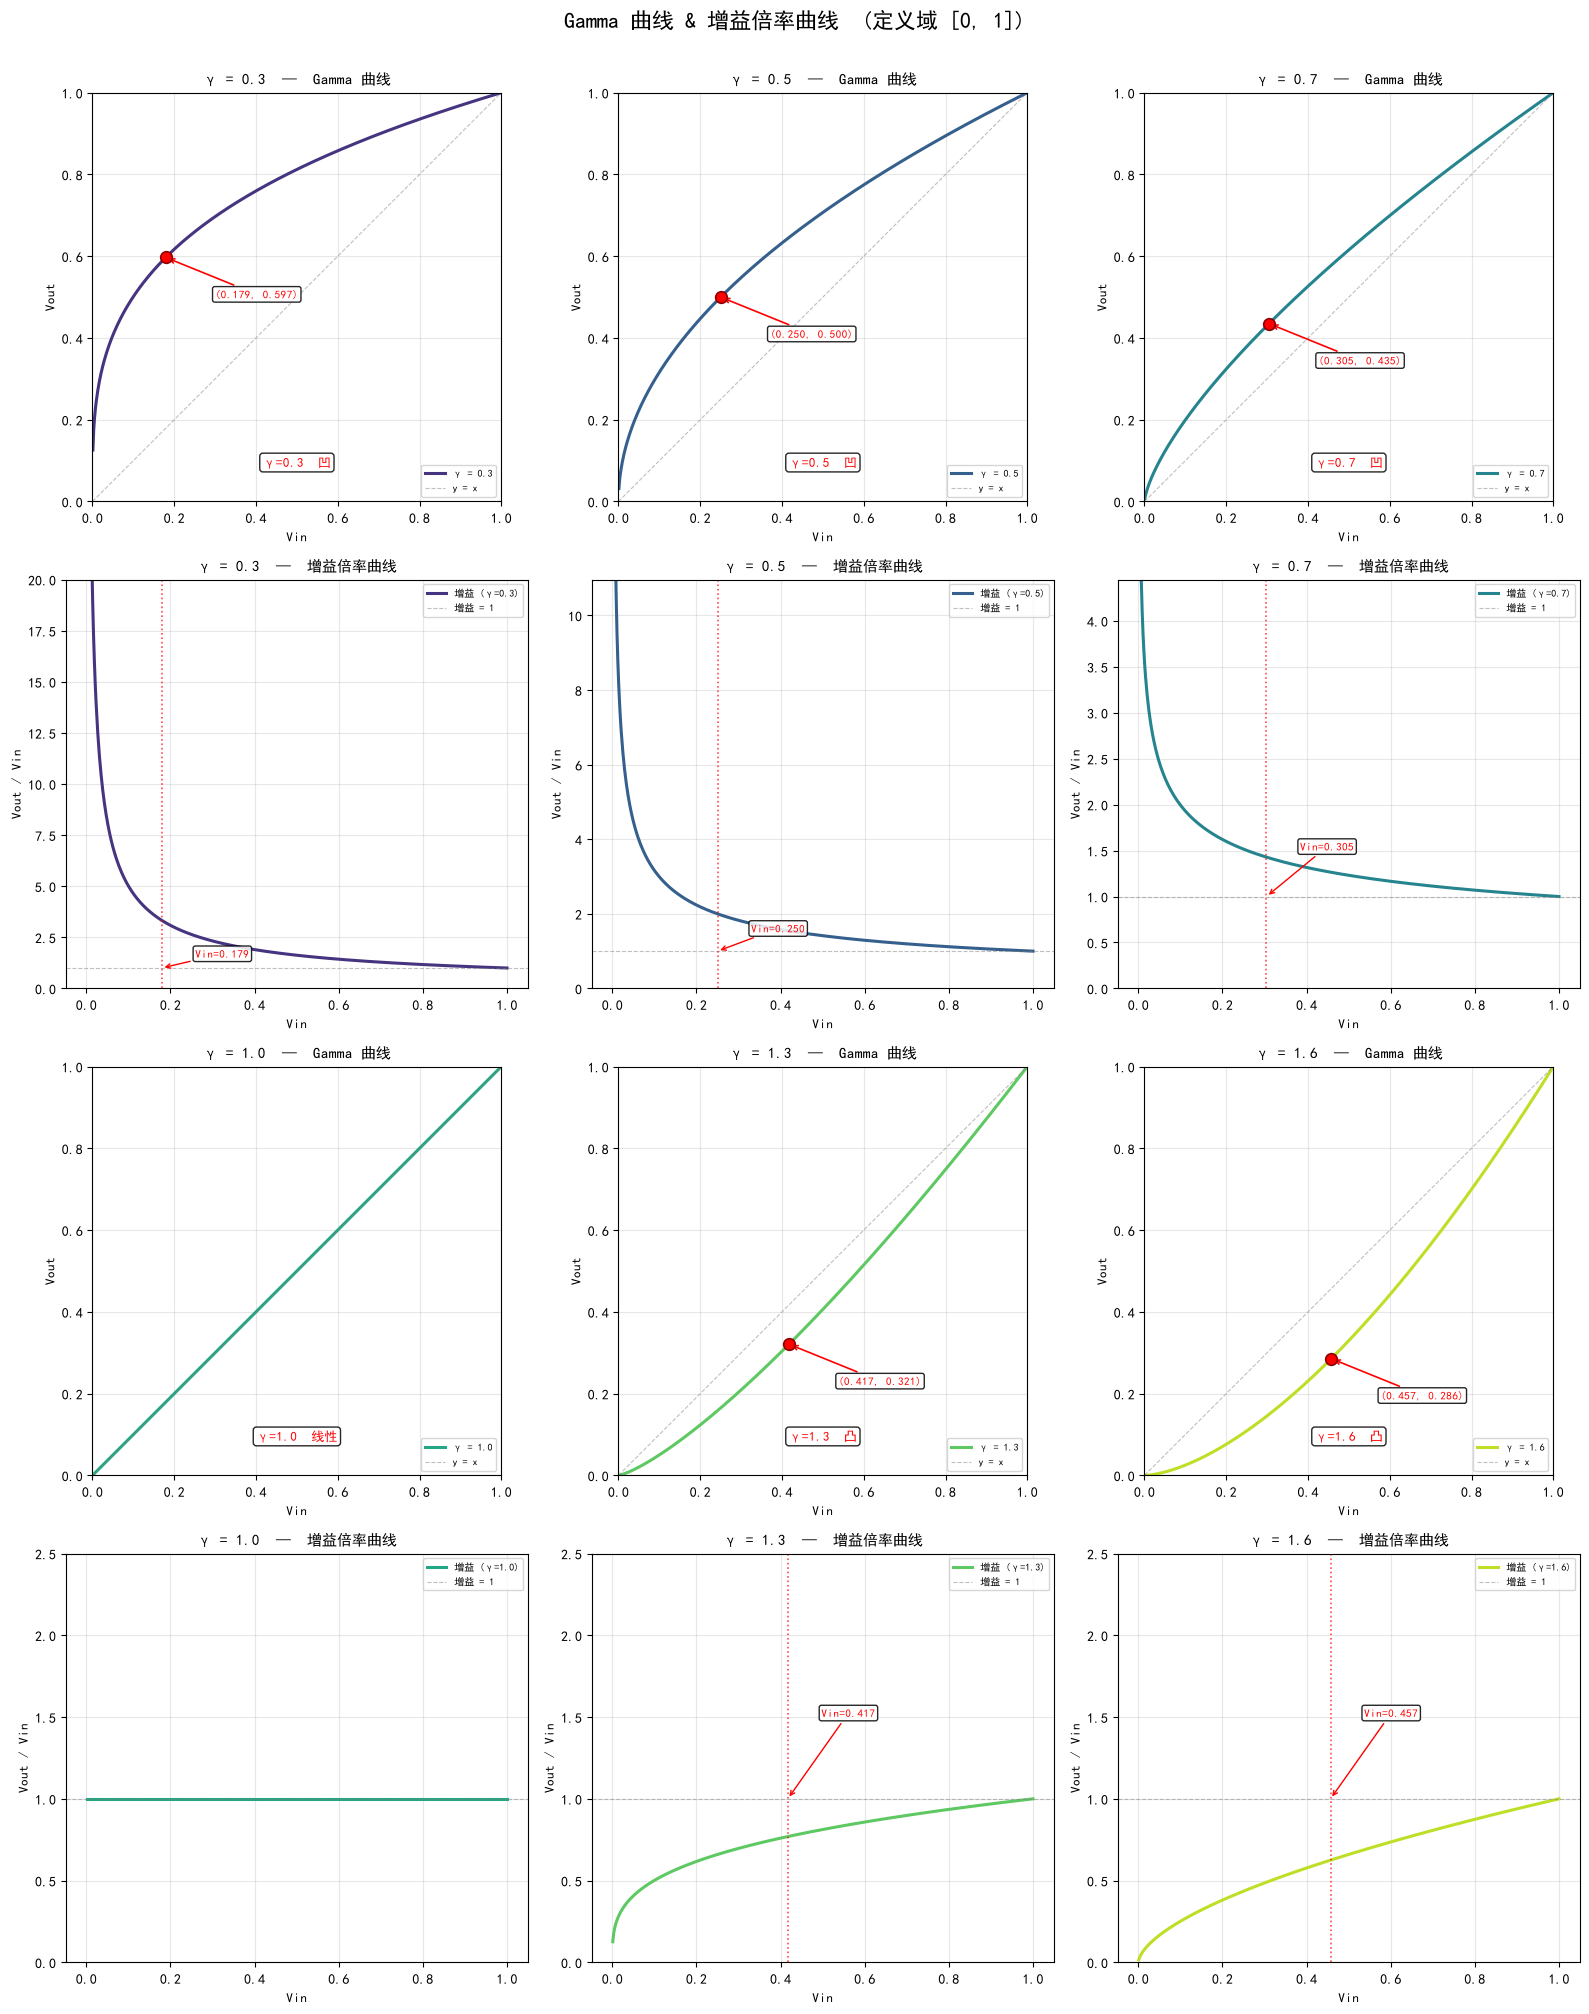

拐点标注说明：
  数学上 f''(x)=γ(γ-1)x^(γ-2) 在 (0,1] 内符号恒定，
  无极值拐点。图中标注的是 y'=1 的点。
--------------------------------------------------------------
  γ = 0.3  →  拐点 Vin* = 0.179,  Vout* = 0.597
  γ = 0.5  →  拐点 Vin* = 0.250,  Vout* = 0.500
  γ = 0.7  →  拐点 Vin* = 0.305,  Vout* = 0.435
  γ = 1.0  →  线性，无过渡点
  γ = 1.3  →  拐点 Vin* = 0.417,  Vout* = 0.321
  γ = 1.6  →  拐点 Vin* = 0.457,  Vout* = 0.286


In [3]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

# ==================== 参数 ====================
gammas = [0.3, 0.5, 0.7, 1.0, 1.3, 1.6]
colors = plt.cm.viridis(np.linspace(0.15, 0.9, len(gammas)))
Vin    = np.linspace(0.001, 1, 500)          # 避免除零

# ==================== 拐点分析 ====================
# 数学拐点: f''(x)=γ(γ-1)x^(γ-2), 在(0,1]内符号恒定 → 无极值拐点
# 这里标注"切线斜率=1"的点 x* = γ^(1/(1-γ)), 即增益为1的过渡点
knee_info = {}
for g in gammas:
    if abs(g - 1.0) < 1e-9:
        knee_info[g] = None
    else:
        x_knee = g ** (1.0 / (1.0 - g))
        if 0 < x_knee <= 1:
            knee_info[g] = (x_knee, x_knee ** g)
        else:
            knee_info[g] = None

# ==================== 4行 × 3列 ====================
# 每列对应一个 γ: 上排=Gamma曲线, 下排=增益曲线
fig, axes = plt.subplots(4, 3, figsize=(16, 20))

for i, g in enumerate(gammas):
    Vout  = Vin ** g
    gain  = Vout / Vin                     # = Vin^(γ-1)

    row_top = (i // 3) * 2                 # gamma 曲线所在行
    row_bot = row_top + 1                  # 增益曲线所在行
    col     = i % 3

    ax_gamma = axes[row_top, col]
    ax_gain  = axes[row_bot, col]

    # ========== 上排: Gamma 曲线 ==========
    ax_gamma.plot(Vin, Vout, color=colors[i], linewidth=2.2,
                  label=f"γ = {g}")
    ax_gamma.plot([0, 1], [0, 1], '--', color='gray',
                  alpha=0.5, linewidth=0.8, label="y = x")

    # 标注拐点 (切线斜率=1 的点)
    if knee_info[g] is not None:
        xk, yk = knee_info[g]
        ax_gamma.scatter(xk, yk, color='red', s=70, zorder=5,
                         edgecolors='darkred', linewidths=1.2)
        ax_gamma.annotate(f"({xk:.3f}, {yk:.3f})",
                          xy=(xk, yk), xytext=(xk + 0.12, yk - 0.1),
                          fontsize=8, color='red',
                          arrowprops=dict(arrowstyle='->', color='red', lw=1.2),
                          bbox=dict(boxstyle='round,pad=0.2',
                                    facecolor='white', alpha=0.85))

    # 凹凸性标签
    if g < 1:
        curve_type = "凹"
    elif g == 1:
        curve_type = "线性"
    else:
        curve_type = "凸"
    ax_gamma.text(0.5, 0.08, f"γ={g}  {curve_type}",
                  transform=ax_gamma.transAxes, fontsize=9,
                  color='red', ha='center', va='bottom',
                  bbox=dict(boxstyle='round,pad=0.25',
                            facecolor='white', alpha=0.85))

    ax_gamma.set_xlim(0, 1);  ax_gamma.set_ylim(0, 1)
    ax_gamma.set_xlabel("Vin", fontsize=9)
    ax_gamma.set_ylabel("Vout", fontsize=9)
    ax_gamma.set_title(f"γ = {g}  —  Gamma 曲线", fontsize=11, fontweight='bold')
    ax_gamma.legend(loc='lower right', fontsize=7, framealpha=0.8)
    ax_gamma.grid(True, alpha=0.3)
    ax_gamma.set_aspect('equal')

    # ========== 下排: 增益曲线 ==========
    ax_gain.plot(Vin, gain, color=colors[i], linewidth=2.2,
                 label=f"增益 (γ={g})")
    ax_gain.axhline(y=1, color='gray', linestyle='--', alpha=0.5,
                    linewidth=0.8, label="增益 = 1")

    # 标注拐点 (增益=1 的位置)
    if knee_info[g] is not None:
        xk, _ = knee_info[g]
        ax_gain.axvline(x=xk, color='red', linestyle=':', alpha=0.7, linewidth=1.2)
        ax_gain.annotate(f"Vin={xk:.3f}",
                         xy=(xk, 1), xytext=(xk + 0.08, 1.5),
                         fontsize=8, color='red',
                         arrowprops=dict(arrowstyle='->', color='red', lw=1.0),
                         bbox=dict(boxstyle='round,pad=0.2',
                                   facecolor='white', alpha=0.85))

    # y 轴裁剪 (增益在 Vin→0 时可能极大)
    gain_max = np.max(gain[Vin >= 0.01])     # 在可见范围内取最大增益
    ymax = max(gain_max * 1.15, 2.5)
    if ymax > 20:
        ymax = 20
    ax_gain.set_ylim(0, ymax)

    ax_gain.set_xlabel("Vin", fontsize=9)
    ax_gain.set_ylabel("Vout / Vin", fontsize=9)
    ax_gain.set_title(f"γ = {g}  —  增益倍率曲线", fontsize=11, fontweight='bold')
    ax_gain.legend(loc='upper right', fontsize=7, framealpha=0.8)
    ax_gain.grid(True, alpha=0.3)

fig.suptitle("Gamma 曲线 & 增益倍率曲线  (定义域 [0, 1])",
             fontsize=16, fontweight='bold', y=1.005)
plt.tight_layout()
plt.show()

# ==================== 打印分析 ====================
print("=" * 62)
print("拐点标注说明：")
print("  数学上 f''(x)=γ(γ-1)x^(γ-2) 在 (0,1] 内符号恒定，")
print("  无极值拐点。图中标注的是 y'=1 的点。")
print("-" * 62)
for g in gammas:
    ki = knee_info[g]
    if ki is None:
        print(f"  γ = {g:.1f}  →  线性，无过渡点")
    else:
        print(f"  γ = {g:.1f}  →  拐点 Vin* = {ki[0]:.3f},  Vout* = {ki[1]:.3f}")
print("=" * 62)
